In [1]:
%pip -q install openai

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\86187\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [7]:
import os, getpass, json, re, time
from dataclasses import dataclass, field
from openai import OpenAI

def _get_openrouter_key():
    k = os.environ.get('MY_PRIVATE_OPENROUTER_KEY') or os.environ.get('OPENROUTER_API_KEY')
    if k: return k
    try:
        from google.colab import userdata
        k = userdata.get('OPENROUTER_API_KEY')
        if k: return k
    except Exception:
        pass
    return getpass.getpass('Paste your OpenRouter API key (hidden): ')

API_KEY = _get_openrouter_key()
client  = OpenAI(base_url='https://openrouter.ai/api/v1', api_key=API_KEY)

GEN_MODEL   = 'openai/gpt-4o-mini'     # the model doing the task
JUDGE_MODEL = 'openai/gpt-4o-mini'     # the model grading it at L2 (see the warning in section 4)
FAST_MODE   = False                    # True -> only the first 5 cases, while you are debugging
TOKENS = {'in': 0, 'out': 0}

def generate(prompt, system=None, model=None, max_new_tokens=350, temperature=0.0):
    """temperature 0 = deterministic. Non-negotiable here: at temperature 1 you cannot tell a
       prompt improvement from sampling luck, and your before/after comparison means nothing."""
    msgs = ([{'role': 'system', 'content': system}] if system else []) + \
           [{'role': 'user', 'content': prompt}]
    r = client.chat.completions.create(model=model or GEN_MODEL, messages=msgs,
                                       temperature=temperature, max_tokens=max_new_tokens)
    if getattr(r, 'usage', None):
        TOKENS['in']  += r.usage.prompt_tokens
        TOKENS['out'] += r.usage.completion_tokens
    return r.choices[0].message.content.strip()

print('connected ·', generate('Reply with exactly the word: ready', max_new_tokens=6))

Paste your OpenRouter API key (hidden):  ········


connected · ready


In [3]:
import urllib.request, json as _json

def credit_check():
    """Ask OpenRouter what is left on your key. Costs nothing."""
    try:
        req = urllib.request.Request('https://openrouter.ai/api/v1/key',
                                     headers={'Authorization': f'Bearer {API_KEY}'})
        d = _json.load(urllib.request.urlopen(req, timeout=20))['data']
        used, cap = d.get('usage'), d.get('limit')
        if cap is None:
            print(f'spent so far: ${used:.4f}   (no cap set on this key)')
        else:
            print(f'spent ${used:.4f} of ${cap:.2f}  ->  ${cap - used:.4f} remaining')
        rl = d.get('rate_limit') or {}
        if rl:
            print(f"rate limit: {rl.get('requests')} requests per {rl.get('interval')}")
    except Exception as e:
        print('could not check credit (not a problem, carry on):', str(e)[:120])

credit_check()

spent $1.0596 of $10.00  ->  $8.9404 remaining
rate limit: -1 requests per 10s


In [8]:
import os
import subprocess

def wsl_bash(script, timeout=900):
    """从 Windows 版 Jupyter 调用 Project3-Ubuntu 里的命令。"""
    env = os.environ.copy()
    env["OPENROUTER_API_KEY"] = API_KEY

    items = [x for x in env.get("WSLENV", "").split(":") if x]
    if not any(x.split("/")[0] == "OPENROUTER_API_KEY" for x in items):
        items.append("OPENROUTER_API_KEY/u")
    env["WSLENV"] = ":".join(items)

    result = subprocess.run(
        ["wsl.exe", "-d", "Project3-Ubuntu", "--", "bash", "-lc", script],
        text=True,
        capture_output=True,
        timeout=timeout,
        env=env,
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"WSL command failed (exit {result.returncode})\n"
            f"STDERR:\n{result.stderr[-4000:]}\n"
            f"STDOUT:\n{result.stdout[-4000:]}"
        )

    return result.stdout

In [11]:
print(
    wsl_bash(
        "env PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin pi --version",
        timeout=30,
    )
)

In [13]:
out = wsl_bash(
    "env PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin pi --version 2>&1; echo CHECK_FINISHED",
    timeout=30,
)
print(repr(out))

'0.73.1\nCHECK_FINISHED\n'


In [9]:
import os
import subprocess

def wsl_bash(script, timeout=900):
    """从 Windows Jupyter 安全地把多行脚本送进 Project3-Ubuntu。"""
    env = os.environ.copy()
    env["OPENROUTER_API_KEY"] = API_KEY

    items = [x for x in env.get("WSLENV", "").split(":") if x]
    if not any(x.split("/")[0] == "OPENROUTER_API_KEY" for x in items):
        items.append("OPENROUTER_API_KEY/u")
    env["WSLENV"] = ":".join(items)

    clean_script = script.replace("\r\n", "\n").replace("\r", "\n")

    result = subprocess.run(
        ["wsl.exe", "-d", "Project3-Ubuntu", "--", "bash", "-s"],
        input=clean_script.encode("utf-8"),
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        timeout=timeout,
        env=env,
    )

    stdout = result.stdout.decode("utf-8", errors="replace")
    stderr = result.stderr.decode("utf-8", errors="replace")

    if result.returncode != 0:
        raise RuntimeError(
            f"WSL command failed (exit {result.returncode})\n"
            f"STDERR:\n{stderr[-4000:]}\n"
            f"STDOUT:\n{stdout[-4000:]}"
        )

    return stdout

In [21]:
check_script = r"""
SAFE_PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

echo "=== PI Agent ==="
env PATH="$SAFE_PATH" pi --version 2>&1 || true

echo
echo "=== Docker ==="
env PATH="$SAFE_PATH" docker version --format '{{.Server.Version}}' 2>&1 || true

echo
echo "=== SkillsBench paper-anonymizer ==="
TASK=/opt/project3/skillsbench-tasks/paper-anonymizer/task.yaml

if [ -f "$TASK" ]; then
    echo "FOUND: $TASK"
    echo
    echo "--- task.yaml preview ---"
    sed -n '1,25p' "$TASK"
else
    echo "NOT FOUND: $TASK"
fi
"""

print(wsl_bash(check_script, timeout=60))

=== PI Agent ===
0.73.1

=== Docker ===
29.9.2

=== SkillsBench paper-anonymizer ===
NOT FOUND: /opt/project3/skillsbench-tasks/paper-anonymizer/task.yaml



In [22]:
search_script = r"""
echo "Searching known SkillsBench folders..."

for ROOT in \
  /opt/project3/skillsbench-tasks \
  /mnt/d/Downloads/skillsbench_v1.1_source \
  /mnt/d/Downloads/skillsbench-1.1
do
  if [ -d "$ROOT" ]; then
    echo
    echo "--- Searching: $ROOT ---"
    find "$ROOT" -type f -path "*/paper-anonymizer/task.yaml" -print 2>/dev/null
  fi
done
"""

print(wsl_bash(search_script, timeout=60))

Searching known SkillsBench folders...

--- Searching: /opt/project3/skillsbench-tasks ---

--- Searching: /mnt/d/Downloads/skillsbench_v1.1_source ---



In [23]:
SKILLSBENCH_ROOT = "/mnt/d/Downloads/skillsbench_v1.1_source/skillsbench-1.1"
TASK_NAME = "paper-anonymizer"
TASK_DIR = f"{SKILLSBENCH_ROOT}/tasks/{TASK_NAME}"
ENV_DIR = f"{TASK_DIR}/environment"

preview_script = f"""
set -eu

echo "=== Task folder ==="
ls -la "{TASK_DIR}"

echo
echo "=== Task brief ==="
sed -n '1,220p' "{TASK_DIR}/task.md"

echo
echo "=== Dockerfile ==="
sed -n '1,160p' "{ENV_DIR}/Dockerfile"

echo
echo "=== Verifier files ==="
find "{TASK_DIR}/verifier" -maxdepth 1 -type f -printf '%f\\n' | sort
"""

print(wsl_bash(preview_script, timeout=60))

=== Task folder ===
total 4
drwxrwxrwx 1 root root 4096 Oct 27 14:56 .
drwxrwxrwx 1 root root 4096 Oct 27 14:56 ..
drwxrwxrwx 1 root root 4096 Oct 27 14:56 environment
drwxrwxrwx 1 root root 4096 Oct 27 14:56 oracle
-rwxrwxrwx 1 root root 1363 Jun 16 15:10 task.md
drwxrwxrwx 1 root root 4096 Oct 27 14:56 verifier

=== Task brief ===
---
schema_version: '1.3'
metadata:
  author_name: Yueqian Lin
  author_email: yl768@duke.edu
  difficulty: medium
  category: office-white-collar
  subcategory: document-editing
  category_confidence: high
  secondary_category: media-content-production
  task_type:
  - transformation
  - detection
  modality:
  - pdf
  interface:
  - terminal
  - python
  skill_type:
  - file-format-knowledge
  - domain-procedure
  tags:
  - pdf
  - redaction
  - anonymization
  - blind-review
verifier:
  type: test-script
  timeout_sec: 300.0
  service: main
  hardening:
    cleanup_conftests: true
agent:
  timeout_sec: 1000.0
environment:
  network_mode: public
  build_t

In [24]:
catalog_script = f"""
set -eu
ROOT="{SKILLSBENCH_ROOT}/tasks"

printf "%-38s %-10s %s\\n" "TASK" "DIFFICULTY" "CATEGORY"
printf "%-38s %-10s %s\\n" "----" "----------" "--------"

for TASK_MD in "$ROOT"/*/task.md; do
    NAME=$(basename "$(dirname "$TASK_MD")")
    DIFFICULTY=$(awk '/^  difficulty:/ {{print $2; exit}}' "$TASK_MD")
    CATEGORY=$(awk '/^  category:/ {{print $2; exit}}' "$TASK_MD")
    printf "%-38s %-10s %s\\n" "$NAME" "${{DIFFICULTY:-unknown}}" "${{CATEGORY:-unknown}}"
done | sort
"""

print(wsl_bash(catalog_script, timeout=60))

TASK                                   DIFFICULTY CATEGORY
----                                   ---------- --------
3d-scan-calc                           hard       industrial-physical-systems
ada-bathroom-plan-repair               hard       industrial-physical-systems
adaptive-cruise-control                medium     industrial-physical-systems
azure-bgp-oscillation-route-leak       medium     software-engineering
bike-rebalance                         medium     mathematics-or-formal-reasoning
citation-check                         medium     office-white-collar
civ6-adjacency-optimizer               hard       mathematics-or-formal-reasoning
court-form-filling                     easy       office-white-collar
crystallographic-wyckoff-position-analysis medium     natural-science
dapt-intrusion-detection               hard       cybersecurity
data-to-d3                             medium     software-engineering
debug-trl-grpo                         hard       software-engineeri

In [25]:
pi_help_script = r"""
SAFE_PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

env PATH="$SAFE_PATH" pi --help 2>&1 | sed -n '1,220p'
"""

print(wsl_bash(pi_help_script, timeout=60))

pi - AI coding assistant with read, bash, edit, write tools

Usage:
  pi [options] [@files...] [messages...]

Commands:
  pi install <source> [-l]     Install extension source and add to settings
  pi remove <source> [-l]      Remove extension source from settings
  pi uninstall <source> [-l]   Alias for remove
  pi update [source|self|pi]   Update pi and installed extensions
  pi list                      List installed extensions from settings
  pi config                    Open TUI to enable/disable package resources
  pi <command> --help          Show help for install/remove/uninstall/update/list

Options:
  --provider <name>              Provider name (default: google)
  --model <pattern>              Model pattern or ID (supports "provider/id" and optional ":<thinking>")
  --api-key <key>                API key (defaults to env vars)
  --system-prompt <text>         System prompt (default: coding assistant prompt)
  --append-system-prompt <text>  Append text or file contents to t

In [26]:
import json

PROVIDER = "openrouter"
MODEL = "openai/gpt-4o-mini"
TOTAL_BUDGET_USD = 9.00

VALIDATION_TASKS = [
    "dialogue-parser",
    "paper-anonymizer",
]

TEST_TASKS = [
    "offer-letter-generator",
    "court-form-filling",
]

DEFAULT_CONFIG = {
    "label": "default",
    "thinking": "off",
    "tool_profile": "default",
    "append_system_prompt": None,
}

SEARCH_SPACE = {
    "thinking": ["off", "minimal", "low", "medium"],
    "tool_profile": {
        "default": None,
        "full": "read,bash,edit,write,grep,find,ls",
    },
    "prompt_style": {
        "default": None,
        "verify": (
            "Complete the task independently. Inspect the required output files "
            "and run the provided verifier before finishing. Do not stop until "
            "the required deliverables exist."
        ),
    },
}

EXPERIMENT_PROTOCOL = {
    "harness": "PI Agent 0.73.1",
    "benchmark": "SkillsBench 1.1",
    "model": MODEL,
    "validation_tasks": VALIDATION_TASKS,
    "test_tasks": TEST_TASKS,
    "methods": [
        "default",
        "random_search",
        "bayesian_optimization",
        "custom_cost_aware_search",
    ],
    "total_budget_usd": TOTAL_BUDGET_USD,
    "rule": (
        "Use validation only to select a configuration. "
        "Run held-out test tasks only after the configuration is frozen."
    ),
}

print(json.dumps(EXPERIMENT_PROTOCOL, indent=2, ensure_ascii=False))
print("\nDefault configuration:")
print(json.dumps(DEFAULT_CONFIG, indent=2, ensure_ascii=False))

{
  "harness": "PI Agent 0.73.1",
  "benchmark": "SkillsBench 1.1",
  "model": "openai/gpt-4o-mini",
  "validation_tasks": [
    "dialogue-parser",
    "paper-anonymizer"
  ],
  "test_tasks": [
    "offer-letter-generator",
    "court-form-filling"
  ],
  "methods": [
    "default",
    "random_search",
    "bayesian_optimization",
    "custom_cost_aware_search"
  ],
  "total_budget_usd": 9.0,
  "rule": "Use validation only to select a configuration. Run held-out test tasks only after the configuration is frozen."
}

Default configuration:
{
  "label": "default",
  "thinking": "off",
  "tool_profile": "default",
  "append_system_prompt": null
}


In [27]:
docker_inventory_script = r"""
SAFE_PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

echo "=== Existing task-related Docker images ==="
env PATH="$SAFE_PATH" docker images --format '{{.Repository}}\t{{.Tag}}\t{{.Size}}' \
  | grep -Ei 'paper|skillsbench|dialogue|offer|court' || true

echo
echo "=== Existing containers (read only) ==="
env PATH="$SAFE_PATH" docker ps -a --format 'table {{.Names}}\t{{.Image}}\t{{.Status}}' || true

echo
echo "=== Docker disk usage ==="
env PATH="$SAFE_PATH" docker system df || true
"""

print(wsl_bash(docker_inventory_script, timeout=60))

=== Existing task-related Docker images ===
paper-anonymizer__87b676f4-main	latest	1.1GB

=== Existing containers (read only) ===
NAMES     IMAGE     STATUS

=== Docker disk usage ===
TYPE            TOTAL     ACTIVE    SIZE      RECLAIMABLE
Images          1         0         1.096GB   1.096GB (99%)
Containers      0         0         0B        0B
Local Volumes   0         0         0B        0B
Build Cache     8         0         1.104GB   1.104GB



In [28]:
bench_help_script = r"""
SAFE_PATH=/opt/project3/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

env PATH="$SAFE_PATH" bench eval run --help 2>&1 | sed -n '1,260p'
"""

print(wsl_bash(bench_help_script, timeout=60))

                                                                                
 Usage: bench eval run [OPTIONS]                                                
                                                                                
 Run an evaluation — single task or batch.                                      
                                                                                
 Sandbox: docker, daytona, or modal.                                            
                                                                                
╭─ Options ────────────────────────────────────────────────────────────────────╮
│ --config                               <path>   YAML config file             │
│ --tasks-dir                            <path>   Local tasks directory        │
│ --source-repo                          <str>    Remote repo as org/repo      │
│                                                 (e.g.                        │
│                           

In [29]:
pi_in_docker_check = r"""
SAFE_PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
IMAGE=paper-anonymizer__87b676f4-main:latest
PI_ROOT=/opt/project3/pi-direct

echo "Starting temporary container check..."
env PATH="$SAFE_PATH" docker run --rm \
  -v "$PI_ROOT:$PI_ROOT:ro" \
  "$IMAGE" \
  bash -lc '
    export PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
    pi --version 2>&1
  '

echo "PI_DOCKER_CHECK_FINISHED"
"""

print(wsl_bash(pi_in_docker_check, timeout=60))

Starting temporary container check...
0.73.1
PI_DOCKER_CHECK_FINISHED



In [31]:
oracle_check_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{TASK_DIR}"
IMAGE="paper-anonymizer__87b676f4-main:latest"
CONTAINER="oracle-paper-anonymizer-$$"

cleanup() {{
    docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}}
trap cleanup EXIT

echo "=== Create temporary Oracle container ==="
docker run -d --name "$CONTAINER" "$IMAGE" sleep infinity >/dev/null

echo "=== Run official Oracle solution ==="
docker cp "$TASK_DIR/oracle/solve.sh" "$CONTAINER:/oracle_solve.sh"
docker exec "$CONTAINER" bash /oracle_solve.sh

echo "=== Run official verifier ==="
docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier"
docker exec "$CONTAINER" bash /verifier/test.sh

echo "=== ORACLE_AND_VERIFIER_PASSED ==="
"""

print(wsl_bash(oracle_check_script, timeout=180))

=== Create temporary Oracle container ===
=== Run official Oracle solution ===
Redacted /root/paper1.pdf -> /root/redacted/paper1.pdf
Redacted /root/paper2.pdf -> /root/redacted/paper2.pdf
Redacted /root/paper3.pdf -> /root/redacted/paper3.pdf
=== Run official verifier ===
============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-8.4.1, pluggy-1.7.0 -- /root/.cache/uv/archive-v0/OLcyTTquRdEXTHvME3jcg/bin/python
cachedir: .pytest_cache
rootdir: /verifier
plugins: json-ctrf-0.3.5
collecting ... collected 6 items

../verifier/test_outputs.py::test_structural_integrity PASSED            [ 16%]
../verifier/test_outputs.py::test_authors_redacted PASSED                [ 33%]
../verifier/test_outputs.py::test_affiliations_redacted PASSED           [ 50%]
../verifier/test_outputs.py::test_identifiers_redacted PASSED            [ 66%]
../verifier/test_outputs.py::test_content_preserved PASSED               [ 83%]
../verifier/test_out

In [10]:
import base64
import json
import re
import shlex
import time
import uuid
from pathlib import Path
import urllib.request

# 结果会保存到当前 notebook 同级目录；也就是你的 D 盘作业文件夹中。
RUNS_DIR = Path.cwd() / "project3_pi_hpo_runs"
RUNS_DIR.mkdir(exist_ok=True)

# 目前已存在的镜像。其他三题的镜像之后再构建。
TASK_IMAGES = {
    "paper-anonymizer": "paper-anonymizer__87b676f4-main:latest",
}

def openrouter_credit_snapshot():
    """读取余额/累计使用额；不会调用模型。"""
    req = urllib.request.Request(
        "https://openrouter.ai/api/v1/key",
        headers={"Authorization": f"Bearer {API_KEY}"},
    )
    data = json.load(urllib.request.urlopen(req, timeout=20))["data"]
    return {
        "used_usd": float(data.get("usage") or 0.0),
        "limit_usd": float(data.get("limit") or TOTAL_BUDGET_USD),
    }

def windows_to_wsl_path(path):
    """把 D:\\... 路径转换为 WSL 可访问的 /mnt/d/... 路径。"""
    command = "PATH=/usr/bin:/bin wslpath -a " + shlex.quote(str(path))
    return wsl_bash(command, timeout=30).strip()

RUNS_DIR_WSL = windows_to_wsl_path(RUNS_DIR)

def resolve_pi_config(config):
    """把 notebook 中的简短配置转成 PI 命令行参数。"""
    tool_profile = config.get("tool_profile", "default")
    tools = SEARCH_SPACE["tool_profile"][tool_profile]

    append_prompt = config.get("append_system_prompt")
    if append_prompt is None and "prompt_style" in config:
        append_prompt = SEARCH_SPACE["prompt_style"][config["prompt_style"]]

    return {
        "label": config.get("label", "unnamed"),
        "thinking": config.get("thinking", "off"),
        "tools": tools or "",
        "append_system_prompt": append_prompt or "",
    }

def run_pi_task(task_name, config, wall_seconds=360):
    """
    在 SkillsBench Docker 容器内运行一次 PI，并保存：
    - PI 输出日志
    - 官方 verifier 输出
    - pass/fail、耗时和 OpenRouter 美元成本
    """
    if task_name not in TASK_IMAGES:
        raise ValueError(
            f"{task_name} 的 Docker 镜像尚未构建。当前可运行：{list(TASK_IMAGES)}"
        )

    pi_config = resolve_pi_config(config)
    run_id = f"{task_name}-{pi_config['label']}-{uuid.uuid4().hex[:8]}"
    run_dir = RUNS_DIR / run_id
    run_dir.mkdir()

    task_dir = f"{SKILLSBENCH_ROOT}/tasks/{task_name}"
    image = TASK_IMAGES[task_name]
    user_prompt = (
        "Read /task.md and complete the task inside this container. "
        "Use the available tools and create every required output file. "
        "Do not merely explain the solution; perform the work."
    )

    def b64(value):
        return base64.b64encode(value.encode("utf-8")).decode("ascii")

    values = {
        "__TASK_DIR_B64__": b64(task_dir),
        "__IMAGE_B64__": b64(image),
        "__RUN_ID_B64__": b64(run_id),
        "__OUT_DIR_B64__": b64(windows_to_wsl_path(run_dir)),
        "__THINKING_B64__": b64(pi_config["thinking"]),
        "__TOOLS_B64__": b64(pi_config["tools"]),
        "__APPEND_B64__": b64(pi_config["append_system_prompt"]),
        "__PROMPT_B64__": b64(user_prompt),
        "__WALL_SECONDS__": str(wall_seconds),
    }

    shell_script = r"""
set -u
export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
PI_ROOT=/opt/project3/pi-direct

decode() { printf '%s' "$1" | base64 -d; }

TASK_DIR=$(decode "__TASK_DIR_B64__")
IMAGE=$(decode "__IMAGE_B64__")
RUN_ID=$(decode "__RUN_ID_B64__")
OUT_DIR=$(decode "__OUT_DIR_B64__")
THINKING=$(decode "__THINKING_B64__")
TOOLS=$(decode "__TOOLS_B64__")
APPEND_PROMPT=$(decode "__APPEND_B64__")
TASK_PROMPT=$(decode "__PROMPT_B64__")
WALL_SECONDS=__WALL_SECONDS__

CONTAINER="pi-run-${RUN_ID}"

cleanup() {
  docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}
trap cleanup EXIT

mkdir -p "$OUT_DIR"

MOUNTS=(
  -v "$PI_ROOT:$PI_ROOT:ro"
  -v "$TASK_DIR/task.md:/task.md:ro"
)

if [ -d "$TASK_DIR/environment/skills" ]; then
  MOUNTS+=(-v "$TASK_DIR/environment/skills:/root/.agents/skills:ro")
fi

echo "Creating task container: $CONTAINER"
docker run -d --name "$CONTAINER" "${MOUNTS[@]}" "$IMAGE" sleep infinity >/dev/null

echo "Running PI (wall cap: ${WALL_SECONDS}s)"
set +e
timeout "$WALL_SECONDS" docker exec -i \
  -e OPENROUTER_API_KEY \
  -e PI_CODING_AGENT_DIR=/tmp/pi-agent \
  -e RUN_THINKING="$THINKING" \
  -e RUN_TOOLS="$TOOLS" \
  -e RUN_APPEND_PROMPT="$APPEND_PROMPT" \
  -e RUN_PROMPT="$TASK_PROMPT" \
  "$CONTAINER" bash -s <<'INNER' > "$OUT_DIR/pi_output.txt" 2>&1
export PATH=/opt/project3/pi-direct/node/bin:/opt/project3/pi-direct/agent/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

ARGS=(--provider openrouter --model openai/gpt-4o-mini --print --no-session --thinking "$RUN_THINKING")

if [ -n "$RUN_TOOLS" ]; then
  ARGS+=(--tools "$RUN_TOOLS")
fi

if [ -n "$RUN_APPEND_PROMPT" ]; then
  ARGS+=(--append-system-prompt "$RUN_APPEND_PROMPT")
fi

pi "${ARGS[@]}" "$RUN_PROMPT"
INNER
PI_EXIT=$?
set -e

docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier" >/dev/null

set +e
docker exec "$CONTAINER" bash /verifier/test.sh > "$OUT_DIR/verifier_output.txt" 2>&1
VERIFIER_EXIT=$?
set -e

printf '{"run_id":"%s","pi_exit":%s,"verifier_exit":%s}\n' \
  "$RUN_ID" "$PI_EXIT" "$VERIFIER_EXIT" > "$OUT_DIR/container_result.json"

echo "__RUN_STATUS__ pi_exit=${PI_EXIT} verifier_exit=${VERIFIER_EXIT} output_dir=${OUT_DIR}"
"""

    for marker, value in values.items():
        shell_script = shell_script.replace(marker, value)

    before = openrouter_credit_snapshot()
    started = time.time()
    terminal_log = wsl_bash(shell_script, timeout=wall_seconds + 120)
    elapsed_seconds = round(time.time() - started, 2)
    after = openrouter_credit_snapshot()

    match = re.search(r"pi_exit=(\d+)\s+verifier_exit=(\d+)", terminal_log)
    pi_exit = int(match.group(1)) if match else None
    verifier_exit = int(match.group(2)) if match else None

    result = {
        "run_id": run_id,
        "task": task_name,
        "config": pi_config,
        "pass_at_1": int(verifier_exit == 0),
        "pi_exit": pi_exit,
        "verifier_exit": verifier_exit,
        "elapsed_seconds": elapsed_seconds,
        "cost_usd": round(after["used_usd"] - before["used_usd"], 6),
        "credit_before_usd": before,
        "credit_after_usd": after,
        "run_directory": str(run_dir),
    }

    (run_dir / "summary.json").write_text(
        json.dumps(result, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    print(json.dumps(result, ensure_ascii=False, indent=2))
    print("\nTerminal summary:")
    print(terminal_log[-1500:])
    return result

print(f"Runner ready. Results will be saved in:\n{RUNS_DIR}")

Runner ready. Results will be saved in:
C:\Users\86187\project3_pi_hpo_runs


In [34]:
DEFAULT_PAPER_RESULT = run_pi_task(
    task_name="paper-anonymizer",
    config=DEFAULT_CONFIG,
    wall_seconds=240,
)

{
  "run_id": "paper-anonymizer-default-fdc002b6",
  "task": "paper-anonymizer",
  "config": {
    "label": "default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 31.41,
  "cost_usd": 0.0,
  "credit_before_usd": {
    "used_usd": 0.08640765,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.08640765,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-default-fdc002b6"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-default-fdc002b6
Running PI (wall cap: 240s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/6203新/project3_pi_hpo_runs/paper-anonymizer-default-fdc002b6



In [35]:
build_dialogue_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK="dialogue-parser"
TASK_DIR="{SKILLSBENCH_ROOT}/tasks/$TASK"
IMAGE="dialogue-parser-local:latest"

if docker image inspect "$IMAGE" >/dev/null 2>&1; then
    echo "Image already exists: $IMAGE"
else
    echo "=== Building $IMAGE ==="
    docker build -t "$IMAGE" "$TASK_DIR/environment"
fi

echo
echo "=== Image ready ==="
docker images "$IMAGE" --format '{{{{.Repository}}}}:{{{{.Tag}}}}  {{{{.Size}}}}'
"""

print(wsl_bash(build_dialogue_script, timeout=600))

TASK_IMAGES["dialogue-parser"] = "dialogue-parser-local:latest"
print("\nRegistered dialogue-parser in TASK_IMAGES.")

=== Building dialogue-parser-local:latest ===

=== Image ready ===
dialogue-parser-local:latest  369MB


Registered dialogue-parser in TASK_IMAGES.


In [37]:
oracle_dialogue_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{SKILLSBENCH_ROOT}/tasks/dialogue-parser"
IMAGE="dialogue-parser-local:latest"
CONTAINER="oracle-dialogue-parser-$$"

cleanup() {{
    docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}}
trap cleanup EXIT

echo "=== Create temporary Oracle container ==="
docker run -d --name "$CONTAINER" "$IMAGE" sleep infinity >/dev/null

echo "=== Copy official Oracle and task skill ==="
docker cp "$TASK_DIR/oracle" "$CONTAINER:/oracle"
docker cp "$TASK_DIR/environment/skills" "$CONTAINER:/skills"

echo "=== Run official Oracle solution ==="
docker exec "$CONTAINER" bash /oracle/solve.sh

echo "=== Run official verifier ==="
docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier"
docker exec "$CONTAINER" bash /verifier/test.sh

echo "=== ORACLE_AND_VERIFIER_PASSED ==="
"""

print(wsl_bash(oracle_dialogue_script, timeout=180))

=== Create temporary Oracle container ===
=== Copy official Oracle and task skill ===
=== Run official Oracle solution ===
Generated /app/dialogue.json with 204 nodes and 321 edges
Solution completed. Checking output...
-rw-r--r-- 1 root root 62985 Oct 27 13:07 dialogue.json
=== Run official verifier ===
============================= test session starts ==============================
platform linux -- Python 3.12.8, pytest-8.3.4, pluggy-1.7.0 -- /usr/local/bin/python3.12
cachedir: .pytest_cache
rootdir: /verifier
plugins: json-ctrf-0.3.6
collecting ... collected 35 items

../verifier/test_outputs.py::test_system_basics[json_structure] PASSED   [  2%]
../verifier/test_outputs.py::test_system_basics[schema_validation] PASSED [  5%]
../verifier/test_outputs.py::test_system_basics[dot_exists] PASSED       [  8%]
../verifier/test_outputs.py::test_system_basics[graph_size] PASSED       [ 11%]
../verifier/test_outputs.py::test_narrative_content[speaker-Narrator] PASSED [ 14%]
../verifier/test

In [38]:
DEFAULT_DIALOGUE_RESULT = run_pi_task(
    task_name="dialogue-parser",
    config=DEFAULT_CONFIG,
    wall_seconds=240,
)

{
  "run_id": "dialogue-parser-default-130db9f6",
  "task": "dialogue-parser",
  "config": {
    "label": "default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 82.55,
  "cost_usd": 0.017808,
  "credit_before_usd": {
    "used_usd": 0.1060329,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.12384075,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\dialogue-parser-default-130db9f6"
}

Terminal summary:
Creating task container: pi-run-dialogue-parser-default-130db9f6
Running PI (wall cap: 240s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/6203新/project3_pi_hpo_runs/dialogue-parser-default-130db9f6



In [39]:
# 1) 修正 paper-anonymizer 的延迟结算成本
paper_summary_path = (
    RUNS_DIR / "paper-anonymizer-default-fdc002b6" / "summary.json"
)

paper_summary = json.loads(
    paper_summary_path.read_text(encoding="utf-8")
)

paper_cost_reconciled = round(
    DEFAULT_DIALOGUE_RESULT["credit_before_usd"]["used_usd"]
    - paper_summary["credit_before_usd"]["used_usd"],
    6,
)

paper_summary["cost_usd_raw_immediate"] = paper_summary["cost_usd"]
paper_summary["cost_usd"] = paper_cost_reconciled
paper_summary["cost_status"] = (
    "reconciled from the next run's pre-run OpenRouter usage snapshot; "
    "the provider usage endpoint settled after the first run ended"
)
paper_summary["credit_settled_before_next_run_usd"] = (
    DEFAULT_DIALOGUE_RESULT["credit_before_usd"]["used_usd"]
)

paper_summary_path.write_text(
    json.dumps(paper_summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# 2) 把已运行的简单题标为 pilot；正式 validation 换为一易一难
PILOT_TASKS = ["dialogue-parser"]
VALIDATION_TASKS = ["paper-anonymizer", "edit-pdf"]

EXPERIMENT_PROTOCOL["pilot_calibration_task"] = PILOT_TASKS
EXPERIMENT_PROTOCOL["validation_tasks"] = VALIDATION_TASKS
EXPERIMENT_PROTOCOL["scope_amendment"] = (
    "Before any held-out test run, dialogue-parser was reclassified as a "
    "pilot calibration task because the default configuration reached the "
    "validation ceiling. edit-pdf was added as a more discriminative "
    "validation task. The test split remains untouched."
)

print(f"Corrected paper-anonymizer cost: ${paper_cost_reconciled:.6f}")
print(f"Known baseline cost total: ${paper_cost_reconciled + DEFAULT_DIALOGUE_RESULT['cost_usd']:.6f}")
print("Final validation tasks:", VALIDATION_TASKS)
print("Held-out test tasks (untouched):", TEST_TASKS)

Corrected paper-anonymizer cost: $0.019625
Known baseline cost total: $0.037433
Final validation tasks: ['paper-anonymizer', 'edit-pdf']
Held-out test tasks (untouched): ['offer-letter-generator', 'court-form-filling']


In [40]:
build_edit_pdf_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK="edit-pdf"
TASK_DIR="{SKILLSBENCH_ROOT}/tasks/$TASK"
IMAGE="edit-pdf-local:latest"

if docker image inspect "$IMAGE" >/dev/null 2>&1; then
    echo "Image already exists: $IMAGE"
else
    echo "=== Building $IMAGE ==="
    docker build -t "$IMAGE" "$TASK_DIR/environment"
fi

echo
echo "=== Image ready ==="
docker images "$IMAGE" --format '{{{{.Repository}}}}:{{{{.Tag}}}}  {{{{.Size}}}}'
"""

print(wsl_bash(build_edit_pdf_script, timeout=600))

TASK_IMAGES["edit-pdf"] = "edit-pdf-local:latest"
print("\nRegistered edit-pdf in TASK_IMAGES.")

=== Building edit-pdf-local:latest ===

=== Image ready ===
edit-pdf-local:latest  1.04GB


Registered edit-pdf in TASK_IMAGES.


In [41]:
oracle_edit_pdf_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{SKILLSBENCH_ROOT}/tasks/edit-pdf"
IMAGE="edit-pdf-local:latest"
CONTAINER="oracle-edit-pdf-$$"

cleanup() {{
    docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}}
trap cleanup EXIT

echo "=== Create temporary Oracle container ==="
docker run -d --name "$CONTAINER" "$IMAGE" sleep infinity >/dev/null

echo "=== Copy official Oracle and task skills ==="
docker cp "$TASK_DIR/oracle" "$CONTAINER:/oracle"
docker cp "$TASK_DIR/environment/skills" "$CONTAINER:/skills"

echo "=== Run official Oracle solution ==="
docker exec "$CONTAINER" bash /oracle/solve.sh

echo "=== Run official verifier ==="
docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier"
docker exec "$CONTAINER" bash /verifier/test.sh

echo "=== ORACLE_AND_VERIFIER_PASSED ==="
"""

print(wsl_bash(oracle_edit_pdf_script, timeout=180))

=== Create temporary Oracle container ===
=== Copy official Oracle and task skills ===
=== Run official Oracle solution ===
Oracle wrote: /root/output/output.pdf
Wrote oracle output to /root/output/output.pdf
=== Run official verifier ===
============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-8.3.4, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /verifier
plugins: json-ctrf-0.3.6
collecting ... collected 9 items

../verifier/test_outputs.py::test_form_student_name PASSED               [ 11%]
../verifier/test_outputs.py::test_redact_student_id PASSED               [ 22%]
../verifier/test_outputs.py::test_form_school_email PASSED               [ 33%]
../verifier/test_outputs.py::test_form_date_of_birth PASSED              [ 44%]
../verifier/test_outputs.py::test_form_phone_number PASSED               [ 55%]
../verifier/test_outputs.py::test_form_appeal_reason PASSED              [ 66%]
../verifier/test_o

In [42]:
credit_now = openrouter_credit_snapshot()

if credit_now["used_usd"] >= 9.50:
    raise RuntimeError(
        f"Safety stop: OpenRouter 已用 ${credit_now['used_usd']:.4f}，"
        "不再启动新的模型任务。"
    )

print(
    f"Starting default edit-pdf baseline. "
    f"OpenRouter used: ${credit_now['used_usd']:.6f} / ${credit_now['limit_usd']:.2f}"
)

DEFAULT_EDIT_PDF_RESULT = run_pi_task(
    task_name="edit-pdf",
    config=DEFAULT_CONFIG,
    wall_seconds=360,
)

Starting default edit-pdf baseline. OpenRouter used: $0.134686 / $10.00
{
  "run_id": "edit-pdf-default-bb48b861",
  "task": "edit-pdf",
  "config": {
    "label": "default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 93.51,
  "cost_usd": 0.013787,
  "credit_before_usd": {
    "used_usd": 0.13468605,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.1484733,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\edit-pdf-default-bb48b861"
}

Terminal summary:
Creating task container: pi-run-edit-pdf-default-bb48b861
Running PI (wall cap: 360s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/6203新/project3_pi_hpo_runs/edit-pdf-default-bb48b861



In [43]:
# 把单次即时成本标记为“待结算”，避免错误归因；
# 后续报告使用每个方法批次的累计美元成本。
run_ids_to_mark_pending = [
    "paper-anonymizer-default-fdc002b6",
    "dialogue-parser-default-130db9f6",
    "edit-pdf-default-bb48b861",
]

for run_id in run_ids_to_mark_pending:
    summary_path = RUNS_DIR / run_id / "summary.json"
    summary = json.loads(summary_path.read_text(encoding="utf-8"))

    summary["cost_usd_immediate_snapshot"] = summary.get("cost_usd")
    summary["cost_usd"] = None
    summary["cost_status"] = (
        "pending batch settlement: OpenRouter usage endpoint can update "
        "after an individual run; report cumulative batch cost instead"
    )

    summary_path.write_text(
        json.dumps(summary, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

baseline_batch = {
    "method": "default",
    "tasks_run": [
        "paper-anonymizer",
        "dialogue-parser (pilot calibration)",
        "edit-pdf",
    ],
    "formal_validation_tasks": [
        "paper-anonymizer",
        "edit-pdf",
    ],
    "formal_validation_pass_at_1": 1.0,
    "usage_before_usd": 0.08640765,
    "usage_after_observed_usd": 0.14847330,
    "cumulative_cost_usd_observed": round(0.14847330 - 0.08640765, 6),
    "note": (
        "Observed after the final baseline run. Individual usage settlement "
        "may lag; use this cumulative method-level amount in analysis."
    ),
}

baseline_batch_path = RUNS_DIR / "baseline_batch_summary.json"
baseline_batch_path.write_text(
    json.dumps(baseline_batch, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(json.dumps(baseline_batch, ensure_ascii=False, indent=2))

{
  "method": "default",
  "tasks_run": [
    "paper-anonymizer",
    "dialogue-parser (pilot calibration)",
    "edit-pdf"
  ],
  "formal_validation_tasks": [
    "paper-anonymizer",
    "edit-pdf"
  ],
  "formal_validation_pass_at_1": 1.0,
  "usage_before_usd": 0.08640765,
  "usage_after_observed_usd": 0.1484733,
  "cumulative_cost_usd_observed": 0.062066,
  "note": "Observed after the final baseline run. Individual usage settlement may lag; use this cumulative method-level amount in analysis."
}


In [44]:
import random
from datetime import datetime, timezone

# 6 个固定候选配置：只优化 PI 已公开支持的参数。
CONFIG_CANDIDATES = [
    {
        "label": "c0_off_default",
        "thinking": "off",
        "tool_profile": "default",
        "prompt_style": "default",
    },
    {
        "label": "c1_off_full_verify",
        "thinking": "off",
        "tool_profile": "full",
        "prompt_style": "verify",
    },
    {
        "label": "c2_minimal_default_verify",
        "thinking": "minimal",
        "tool_profile": "default",
        "prompt_style": "verify",
    },
    {
        "label": "c3_minimal_full_verify",
        "thinking": "minimal",
        "tool_profile": "full",
        "prompt_style": "verify",
    },
    {
        "label": "c4_low_default_verify",
        "thinking": "low",
        "tool_profile": "default",
        "prompt_style": "verify",
    },
    {
        "label": "c5_low_full_verify",
        "thinking": "low",
        "tool_profile": "full",
        "prompt_style": "verify",
    },
]

# 每种搜索方法都最多使用 6 次 validation rollout。
# Default 只有 2 次：每道 validation 题各运行一次。
HPO_PROTOCOL = {
    "frozen_at_utc": datetime.now(timezone.utc).isoformat(),
    "harness": "PI Agent 0.73.1",
    "benchmark": "SkillsBench 1.1",
    "model": MODEL,
    "validation_tasks": VALIDATION_TASKS,
    "held_out_test_tasks": TEST_TASKS,
    "objective": (
        "Maximize validation pass@1; among configurations with equal pass@1, "
        "minimize cumulative USD cost."
    ),
    "candidate_configs": CONFIG_CANDIDATES,
    "methods": {
        "default": {
            "rollout_budget": 2,
            "configuration": "DEFAULT_CONFIG",
        },
        "random_search": {
            "rollout_budget": 6,
            "selection": "sample 3 distinct configurations uniformly with seed 6203; run each on both validation tasks",
            "seed": 6203,
        },
        "bayesian_optimization": {
            "rollout_budget": 6,
            "selection": (
                "3 sequential categorical Thompson-sampling selections; "
                "each selected configuration runs on both validation tasks"
            ),
        },
        "custom_cost_aware_search": {
            "rollout_budget": 6,
            "selection": (
                "Stage 1: run 4 configurations on cheaper paper-anonymizer; "
                "Stage 2: promote the top 2 by pass then cost to edit-pdf"
            ),
        },
    },
    "test_policy": "Held-out test tasks will run only after one final configuration is chosen.",
}

HPO_PROTOCOL_PATH = RUNS_DIR / "hpo_protocol_frozen.json"
HPO_PROTOCOL_PATH.write_text(
    json.dumps(HPO_PROTOCOL, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

random_plan = random.Random(6203).sample(CONFIG_CANDIDATES, 3)

print("Protocol frozen:", HPO_PROTOCOL_PATH)
print("\nRandom-search configurations:")
for config in random_plan:
    print("-", config["label"])

Protocol frozen: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs\hpo_protocol_frozen.json

Random-search configurations:
- c1_off_full_verify
- c2_minimal_default_verify
- c0_off_default


In [45]:
def get_config(label):
    for config in CONFIG_CANDIDATES:
        if config["label"] == label:
            return config
    raise KeyError(f"Unknown configuration: {label}")

random_batch_start = openrouter_credit_snapshot()
if random_batch_start["used_usd"] >= 9.50:
    raise RuntimeError("Safety stop: OpenRouter usage is too close to the limit.")

RANDOM_RESULTS = []

random_config_1 = get_config("c1_off_full_verify")

print("Random search, configuration 1/3:", random_config_1["label"])
print(
    f"Batch starting usage: "
    f"${random_batch_start['used_usd']:.6f} / ${random_batch_start['limit_usd']:.2f}"
)

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="paper-anonymizer",
        config=random_config_1,
        wall_seconds=300,
    )
)

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="edit-pdf",
        config=random_config_1,
        wall_seconds=360,
    )
)

print("\nCompleted random-search configuration 1/3.")

Random search, configuration 1/3: c1_off_full_verify
Batch starting usage: $0.158049 / $10.00
{
  "run_id": "paper-anonymizer-c1_off_full_verify-2ce7dbce",
  "task": "paper-anonymizer",
  "config": {
    "label": "c1_off_full_verify",
    "thinking": "off",
    "tools": "read,bash,edit,write,grep,find,ls",
    "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 113.8,
  "cost_usd": 0.01542,
  "credit_before_usd": {
    "used_usd": 0.15804915,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.17346945,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c1_off_full_verify-2ce7dbce"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c1_off

In [46]:
random_config_2 = get_config("c2_minimal_default_verify")

print("Random search, configuration 2/3:", random_config_2["label"])

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="paper-anonymizer",
        config=random_config_2,
        wall_seconds=300,
    )
)

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="edit-pdf",
        config=random_config_2,
        wall_seconds=360,
    )
)

print("\nCompleted random-search configuration 2/3.")

Random search, configuration 2/3: c2_minimal_default_verify
{
  "run_id": "paper-anonymizer-c2_minimal_default_verify-ffffac3f",
  "task": "paper-anonymizer",
  "config": {
    "label": "c2_minimal_default_verify",
    "thinking": "minimal",
    "tools": "",
    "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 259.87,
  "cost_usd": 0.05403,
  "credit_before_usd": {
    "used_usd": 0.22470525,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.27873555,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c2_minimal_default_verify-ffffac3f"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c2_minimal_default_verify-ffffac3f
Running PI (

In [47]:
random_config_3 = get_config("c0_off_default")

print("Random search, configuration 3/3:", random_config_3["label"])

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="paper-anonymizer",
        config=random_config_3,
        wall_seconds=300,
    )
)

RANDOM_RESULTS.append(
    run_pi_task(
        task_name="edit-pdf",
        config=random_config_3,
        wall_seconds=360,
    )
)

print("\nCompleted random-search configuration 3/3.")

Random search, configuration 3/3: c0_off_default
{
  "run_id": "paper-anonymizer-c0_off_default-cf7b42ad",
  "task": "paper-anonymizer",
  "config": {
    "label": "c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 79.22,
  "cost_usd": 0.000403,
  "credit_before_usd": {
    "used_usd": 0.33647235,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.33687525,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c0_off_default-cf7b42ad"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c0_off_default-cf7b42ad
Running PI (wall cap: 300s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/6203新/project3_pi_hpo_runs/paper-anonymizer-c0_off_default-cf7b42ad

{
  "run_id": "edit-pdf-c0_off_defa

In [48]:
from collections import defaultdict

random_end_observed = RANDOM_RESULTS[-1]["credit_after_usd"]["used_usd"]

by_config = defaultdict(list)
for result in RANDOM_RESULTS:
    by_config[result["config"]["label"]].append(result)

random_config_summary = []
for label, rows in by_config.items():
    random_config_summary.append({
        "label": label,
        "validation_runs": len(rows),
        "passes": sum(row["pass_at_1"] for row in rows),
        "pass_at_1": round(
            sum(row["pass_at_1"] for row in rows) / len(rows), 3
        ),
        "elapsed_seconds_total": round(
            sum(row["elapsed_seconds"] for row in rows), 2
        ),
        "immediate_cost_estimate_usd": round(
            sum(row.get("cost_usd") or 0 for row in rows), 6
        ),
    })

random_batch_summary = {
    "method": "random_search",
    "seed": 6203,
    "configuration_order": [c["label"] for c in random_plan],
    "formal_validation_tasks": VALIDATION_TASKS,
    "configuration_results": random_config_summary,
    "usage_before_usd": random_batch_start["used_usd"],
    "usage_after_observed_usd": random_end_observed,
    "cumulative_cost_usd_observed": round(
        random_end_observed - random_batch_start["used_usd"], 6
    ),
    "note": (
        "Cumulative batch cost is the primary cost metric. "
        "Per-run immediate costs are retained only as estimates because "
        "OpenRouter usage settlement can lag."
    ),
}

random_summary_path = RUNS_DIR / "random_search_batch_summary.json"
random_summary_path.write_text(
    json.dumps(random_batch_summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(json.dumps(random_batch_summary, ensure_ascii=False, indent=2))

{
  "method": "random_search",
  "seed": 6203,
  "configuration_order": [
    "c1_off_full_verify",
    "c2_minimal_default_verify",
    "c0_off_default"
  ],
  "formal_validation_tasks": [
    "paper-anonymizer",
    "edit-pdf"
  ],
  "configuration_results": [
    {
      "label": "c1_off_full_verify",
      "validation_runs": 2,
      "passes": 2,
      "pass_at_1": 1.0,
      "elapsed_seconds_total": 135.64,
      "immediate_cost_estimate_usd": 0.045618
    },
    {
      "label": "c2_minimal_default_verify",
      "validation_runs": 2,
      "passes": 2,
      "pass_at_1": 1.0,
      "elapsed_seconds_total": 359.29,
      "immediate_cost_estimate_usd": 0.100837
    },
    {
      "label": "c0_off_default",
      "validation_runs": 2,
      "passes": 2,
      "pass_at_1": 1.0,
      "elapsed_seconds_total": 181.95,
      "immediate_cost_estimate_usd": 0.046724
    }
  ],
  "usage_before_usd": 0.15804915,
  "usage_after_observed_usd": 0.3831963,
  "cumulative_cost_usd_observed": 0.2

In [49]:
BAYES_RNG = random.Random(6204)

BAYES_STATE = {
    config["label"]: {
        "alpha": 1,          # Beta(1, 1) 无信息先验
        "beta": 1,
        "observed_costs": [],
        "observed_runs": 0,
    }
    for config in CONFIG_CANDIDATES
}

BAYES_RESULTS = []
BAYES_HISTORY = []

def select_bayesian_config():
    """
    Thompson sampling:
    从每个配置成功率的 Beta 后验抽样，选择抽样成功率最高者；
    若抽样值接近，则优先选择当前估计成本较低的配置。
    """
    candidates = []

    for config in CONFIG_CANDIDATES:
        state = BAYES_STATE[config["label"]]

        sampled_success = BAYES_RNG.betavariate(
            state["alpha"],
            state["beta"],
        )

        expected_cost = (
            sum(state["observed_costs"]) / len(state["observed_costs"])
            if state["observed_costs"]
            else 0.04  # 未试配置的保守成本先验（美元）
        )

        candidates.append({
            "config": config,
            "sampled_success": sampled_success,
            "expected_cost": expected_cost,
        })

    candidates.sort(
        key=lambda item: (
            item["sampled_success"],
            -item["expected_cost"],
        ),
        reverse=True,
    )

    return candidates[0], candidates

def update_bayesian_state(config, results):
    state = BAYES_STATE[config["label"]]

    for result in results:
        state["alpha"] += result["pass_at_1"]
        state["beta"] += 1 - result["pass_at_1"]

        if result.get("cost_usd") is not None:
            state["observed_costs"].append(result["cost_usd"])

        state["observed_runs"] += 1

BAYES_BATCH_START = openrouter_credit_snapshot()

if BAYES_BATCH_START["used_usd"] >= 9.50:
    raise RuntimeError("Safety stop: OpenRouter usage is too close to the limit.")

BAYES_CHOICE_1, BAYES_SCORES_1 = select_bayesian_config()

print(
    "Bayesian round 1 selected:",
    BAYES_CHOICE_1["config"]["label"],
)
print(
    f"Sampled success probability: "
    f"{BAYES_CHOICE_1['sampled_success']:.3f}"
)
print(
    f"Batch starting usage: "
    f"${BAYES_BATCH_START['used_usd']:.6f} / "
    f"${BAYES_BATCH_START['limit_usd']:.2f}"
)

Bayesian round 1 selected: c1_off_full_verify
Sampled success probability: 0.981
Batch starting usage: $0.440430 / $10.00


In [50]:
BAYES_CONFIG_1 = BAYES_CHOICE_1["config"]
BAYES_ROUND_1_RESULTS = []

print("Bayesian round 1 running:", BAYES_CONFIG_1["label"])

for task_name, wall_seconds in [
    ("paper-anonymizer", 300),
    ("edit-pdf", 360),
]:
    result = run_pi_task(
        task_name=task_name,
        config=BAYES_CONFIG_1,
        wall_seconds=wall_seconds,
    )
    BAYES_ROUND_1_RESULTS.append(result)
    BAYES_RESULTS.append(result)

update_bayesian_state(BAYES_CONFIG_1, BAYES_ROUND_1_RESULTS)

BAYES_HISTORY.append({
    "round": 1,
    "config_label": BAYES_CONFIG_1["label"],
    "sampled_success": BAYES_CHOICE_1["sampled_success"],
    "results": BAYES_ROUND_1_RESULTS,
})

print("\nBayesian round 1 completed.")
print("Updated state:", BAYES_STATE[BAYES_CONFIG_1["label"]])

Bayesian round 1 running: c1_off_full_verify
{
  "run_id": "paper-anonymizer-c1_off_full_verify-9a901601",
  "task": "paper-anonymizer",
  "config": {
    "label": "c1_off_full_verify",
    "thinking": "off",
    "tools": "read,bash,edit,write,grep,find,ls",
    "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 75.51,
  "cost_usd": 0.0009,
  "credit_before_usd": {
    "used_usd": 0.44043045,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.44133015,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c1_off_full_verify-9a901601"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c1_off_full_verify-9a901601
Running PI (wall cap: 300s)


In [51]:
BAYES_CHOICE_2, BAYES_SCORES_2 = select_bayesian_config()

print(
    "Bayesian round 2 selected:",
    BAYES_CHOICE_2["config"]["label"],
)
print(
    f"Sampled success probability: "
    f"{BAYES_CHOICE_2['sampled_success']:.3f}"
)
print(
    f"Expected-cost estimate: "
    f"${BAYES_CHOICE_2['expected_cost']:.6f}"
)

Bayesian round 2 selected: c2_minimal_default_verify
Sampled success probability: 0.966
Expected-cost estimate: $0.040000


In [52]:
BAYES_CONFIG_2 = BAYES_CHOICE_2["config"]
BAYES_ROUND_2_RESULTS = []

print("Bayesian round 2 running:", BAYES_CONFIG_2["label"])

for task_name, wall_seconds in [
    ("paper-anonymizer", 300),
    ("edit-pdf", 360),
]:
    result = run_pi_task(
        task_name=task_name,
        config=BAYES_CONFIG_2,
        wall_seconds=wall_seconds,
    )
    BAYES_ROUND_2_RESULTS.append(result)
    BAYES_RESULTS.append(result)

update_bayesian_state(BAYES_CONFIG_2, BAYES_ROUND_2_RESULTS)

BAYES_HISTORY.append({
    "round": 2,
    "config_label": BAYES_CONFIG_2["label"],
    "sampled_success": BAYES_CHOICE_2["sampled_success"],
    "results": BAYES_ROUND_2_RESULTS,
})

print("\nBayesian round 2 completed.")
print("Updated state:", BAYES_STATE[BAYES_CONFIG_2["label"]])

Bayesian round 2 running: c2_minimal_default_verify
{
  "run_id": "paper-anonymizer-c2_minimal_default_verify-ed9b09d1",
  "task": "paper-anonymizer",
  "config": {
    "label": "c2_minimal_default_verify",
    "thinking": "minimal",
    "tools": "",
    "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 153.29,
  "cost_usd": 0.048827,
  "credit_before_usd": {
    "used_usd": 0.50825715,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.5570844,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c2_minimal_default_verify-ed9b09d1"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c2_minimal_default_verify-ed9b09d1
Running PI (wall cap

In [53]:
BAYES_CHOICE_3, BAYES_SCORES_3 = select_bayesian_config()

print(
    "Bayesian round 3 selected:",
    BAYES_CHOICE_3["config"]["label"],
)
print(
    f"Sampled success probability: "
    f"{BAYES_CHOICE_3['sampled_success']:.3f}"
)
print(
    f"Expected-cost estimate: "
    f"${BAYES_CHOICE_3['expected_cost']:.6f}"
)

Bayesian round 3 selected: c1_off_full_verify
Sampled success probability: 0.946
Expected-cost estimate: $0.027962


In [54]:
BAYES_CONFIG_3 = BAYES_CHOICE_3["config"]
BAYES_ROUND_3_RESULTS = []

print("Bayesian round 3 running:", BAYES_CONFIG_3["label"])

for task_name, wall_seconds in [
    ("paper-anonymizer", 300),
    ("edit-pdf", 360),
]:
    result = run_pi_task(
        task_name=task_name,
        config=BAYES_CONFIG_3,
        wall_seconds=wall_seconds,
    )
    BAYES_ROUND_3_RESULTS.append(result)
    BAYES_RESULTS.append(result)

update_bayesian_state(BAYES_CONFIG_3, BAYES_ROUND_3_RESULTS)

BAYES_HISTORY.append({
    "round": 3,
    "config_label": BAYES_CONFIG_3["label"],
    "sampled_success": BAYES_CHOICE_3["sampled_success"],
    "results": BAYES_ROUND_3_RESULTS,
})

print("\nBayesian round 3 completed.")
print("Updated state:", BAYES_STATE[BAYES_CONFIG_3["label"]])

Bayesian round 3 running: c1_off_full_verify
{
  "run_id": "paper-anonymizer-c1_off_full_verify-0701c5ff",
  "task": "paper-anonymizer",
  "config": {
    "label": "c1_off_full_verify",
    "thinking": "off",
    "tools": "read,bash,edit,write,grep,find,ls",
    "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 99.37,
  "cost_usd": 0.043118,
  "credit_before_usd": {
    "used_usd": 0.5731638,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.61628205,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c1_off_full_verify-0701c5ff"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c1_off_full_verify-0701c5ff
Running PI (wall cap: 300s)

In [55]:
bayes_end_observed = BAYES_RESULTS[-1]["credit_after_usd"]["used_usd"]

by_config = defaultdict(list)
for result in BAYES_RESULTS:
    by_config[result["config"]["label"]].append(result)

bayes_config_summary = []
for label, rows in by_config.items():
    bayes_config_summary.append({
        "label": label,
        "validation_runs": len(rows),
        "passes": sum(row["pass_at_1"] for row in rows),
        "pass_at_1": round(
            sum(row["pass_at_1"] for row in rows) / len(rows), 3
        ),
        "elapsed_seconds_total": round(
            sum(row["elapsed_seconds"] for row in rows), 2
        ),
        "immediate_cost_estimate_usd": round(
            sum(row.get("cost_usd") or 0 for row in rows), 6
        ),
        "posterior_alpha": BAYES_STATE[label]["alpha"],
        "posterior_beta": BAYES_STATE[label]["beta"],
    })

bayes_batch_summary = {
    "method": "bayesian_optimization_thompson_sampling",
    "formal_validation_tasks": VALIDATION_TASKS,
    "round_history": BAYES_HISTORY,
    "configuration_results": bayes_config_summary,
    "usage_before_usd": BAYES_BATCH_START["used_usd"],
    "usage_after_observed_usd": bayes_end_observed,
    "cumulative_cost_usd_observed": round(
        bayes_end_observed - BAYES_BATCH_START["used_usd"], 6
    ),
    "note": (
        "Categorical Thompson sampling with Beta-Bernoulli success posteriors. "
        "Cumulative batch cost is the primary cost metric."
    ),
}

bayes_summary_path = RUNS_DIR / "bayesian_optimization_batch_summary.json"
bayes_summary_path.write_text(
    json.dumps(bayes_batch_summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(json.dumps(bayes_batch_summary, ensure_ascii=False, indent=2))

{
  "method": "bayesian_optimization_thompson_sampling",
  "formal_validation_tasks": [
    "paper-anonymizer",
    "edit-pdf"
  ],
  "round_history": [
    {
      "round": 1,
      "config_label": "c1_off_full_verify",
      "sampled_success": 0.9807632598237012,
      "results": [
        {
          "run_id": "paper-anonymizer-c1_off_full_verify-9a901601",
          "task": "paper-anonymizer",
          "config": {
            "label": "c1_off_full_verify",
            "thinking": "off",
            "tools": "read,bash,edit,write,grep,find,ls",
            "append_system_prompt": "Complete the task independently. Inspect the required output files and run the provided verifier before finishing. Do not stop until the required deliverables exist."
          },
          "pass_at_1": 1,
          "pi_exit": 0,
          "verifier_exit": 0,
          "elapsed_seconds": 75.51,
          "cost_usd": 0.0009,
          "credit_before_usd": {
            "used_usd": 0.44043045,
            "

In [56]:
CUSTOM_STAGE1_LABELS = [
    "c0_off_default",
    "c1_off_full_verify",
    "c2_minimal_default_verify",
    "c3_minimal_full_verify",
]

CUSTOM_RESULTS = []
CUSTOM_BATCH_START = openrouter_credit_snapshot()

if CUSTOM_BATCH_START["used_usd"] >= 9.50:
    raise RuntimeError("Safety stop: OpenRouter usage is too close to the limit.")

print("Custom cost-aware search — Stage 1")
print("Configs:", CUSTOM_STAGE1_LABELS)
print(
    f"Batch starting usage: "
    f"${CUSTOM_BATCH_START['used_usd']:.6f} / "
    f"${CUSTOM_BATCH_START['limit_usd']:.2f}"
)

for label in CUSTOM_STAGE1_LABELS:
    config = get_config(label)
    print(f"\nStage 1 running: {label}")
    result = run_pi_task(
        task_name="paper-anonymizer",
        config=config,
        wall_seconds=300,
    )
    CUSTOM_RESULTS.append(result)

def stage1_rank_key(result):
    immediate_cost = (
        result["cost_usd"]
        if result.get("cost_usd") is not None
        else float("inf")
    )
    return (
        -result["pass_at_1"],   # pass 优先
        immediate_cost,         # 再看成本
        result["elapsed_seconds"],
    )

CUSTOM_PROMOTED = sorted(
    CUSTOM_RESULTS,
    key=stage1_rank_key,
)[:2]

print("\nStage 1 completed.")
print("Promoted to Stage 2:")
for result in CUSTOM_PROMOTED:
    print(
        f"- {result['config']['label']} | "
        f"pass={result['pass_at_1']} | "
        f"immediate_cost=${result['cost_usd']:.6f} | "
        f"time={result['elapsed_seconds']:.2f}s"
    )

Custom cost-aware search — Stage 1
Configs: ['c0_off_default', 'c1_off_full_verify', 'c2_minimal_default_verify', 'c3_minimal_full_verify']
Batch starting usage: $0.714610 / $10.00

Stage 1 running: c0_off_default
{
  "run_id": "paper-anonymizer-c0_off_default-b2b6c1d6",
  "task": "paper-anonymizer",
  "config": {
    "label": "c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 235.65,
  "cost_usd": 0.000403,
  "credit_before_usd": {
    "used_usd": 0.7146096,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 0.7150125,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\paper-anonymizer-c0_off_default-b2b6c1d6"
}

Terminal summary:
Creating task container: pi-run-paper-anonymizer-c0_off_default-b2b6c1d6
Running PI (wall cap: 300s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 out

In [57]:
CUSTOM_STAGE2_RESULTS = []

print("Custom cost-aware search — Stage 2")

for stage1_result in CUSTOM_PROMOTED:
    config = get_config(stage1_result["config"]["label"])

    print(f"\nStage 2 running: {config['label']}")
    result = run_pi_task(
        task_name="edit-pdf",
        config=config,
        wall_seconds=360,
    )

    CUSTOM_STAGE2_RESULTS.append(result)
    CUSTOM_RESULTS.append(result)

print("\nCustom cost-aware search completed.")

Custom cost-aware search — Stage 2

Stage 2 running: c0_off_default
{
  "run_id": "edit-pdf-c0_off_default-1bb8ebc5",
  "task": "edit-pdf",
  "config": {
    "label": "c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 124,
  "verifier_exit": 0,
  "elapsed_seconds": 365.82,
  "cost_usd": 0.039521,
  "credit_before_usd": {
    "used_usd": 0.97504065,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 1.01456205,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\edit-pdf-c0_off_default-1bb8ebc5"
}

Terminal summary:
Creating task container: pi-run-edit-pdf-c0_off_default-1bb8ebc5
Running PI (wall cap: 360s)
__RUN_STATUS__ pi_exit=124 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/6203新/project3_pi_hpo_runs/edit-pdf-c0_off_default-1bb8ebc5


Stage 2 running: c1_off_full_verify
{
  "run_id": 

In [58]:
from collections import defaultdict

# 汇总本次自定义方法的批次成本与晋级记录
custom_end_observed = CUSTOM_RESULTS[-1]["credit_after_usd"]["used_usd"]

custom_batch_summary = {
    "method": "custom_cost_aware_search",
    "stage_1_task": "paper-anonymizer",
    "stage_1_labels": CUSTOM_STAGE1_LABELS,
    "stage_2_task": "edit-pdf",
    "promoted_labels": [
        result["config"]["label"] for result in CUSTOM_PROMOTED
    ],
    "rollout_budget": len(CUSTOM_RESULTS),
    "usage_before_usd": CUSTOM_BATCH_START["used_usd"],
    "usage_after_observed_usd": custom_end_observed,
    "cumulative_cost_usd_observed": round(
        custom_end_observed - CUSTOM_BATCH_START["used_usd"], 6
    ),
}

(RUNS_DIR / "custom_cost_aware_batch_summary.json").write_text(
    json.dumps(custom_batch_summary, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# 读取所有正式 validation 运行结果。
# dialogue-parser 是 pilot，不参与最终配置选择。
all_validation_runs = []

for summary_path in RUNS_DIR.glob("*/summary.json"):
    item = json.loads(summary_path.read_text(encoding="utf-8"))

    if item["task"] not in VALIDATION_TASKS:
        continue

    label = item["config"]["label"]

    # 最初的 default baseline 等价于 c0_off_default。
    if label == "default":
        label = "c0_off_default"

    if label not in {c["label"] for c in CONFIG_CANDIDATES}:
        continue

    immediate_cost = item.get("cost_usd")
    if immediate_cost is None:
        immediate_cost = item.get("cost_usd_immediate_snapshot", 0.0)

    all_validation_runs.append({
        "label": label,
        "task": item["task"],
        "pass_at_1": item["pass_at_1"],
        "elapsed_seconds": item["elapsed_seconds"],
        "immediate_cost_estimate_usd": immediate_cost or 0.0,
    })

# 每个配置的 validation 汇总
by_label = defaultdict(list)
for row in all_validation_runs:
    by_label[row["label"]].append(row)

config_metrics = []

for label, rows in by_label.items():
    tasks_seen = sorted({row["task"] for row in rows})

    config_metrics.append({
        "label": label,
        "runs": len(rows),
        "tasks_seen": tasks_seen,
        "pass_rate": round(
            sum(row["pass_at_1"] for row in rows) / len(rows), 3
        ),
        "mean_elapsed_seconds": round(
            sum(row["elapsed_seconds"] for row in rows) / len(rows), 2
        ),
        "mean_immediate_cost_estimate_usd": round(
            sum(row["immediate_cost_estimate_usd"] for row in rows) / len(rows),
            6,
        ),
    })

# 只有两道正式 validation 题都跑过的配置，才有资格进入最终选择。
eligible = [
    metric for metric in config_metrics
    if set(metric["tasks_seen"]) == set(VALIDATION_TASKS)
]

# 冻结的选择规则：
# pass rate 高优先；若相同，平均即时成本估计低优先；最后用平均耗时打破平局。
eligible.sort(
    key=lambda metric: (
        -metric["pass_rate"],
        metric["mean_immediate_cost_estimate_usd"],
        metric["mean_elapsed_seconds"],
    )
)

FINAL_SELECTION = eligible[0]
FINAL_CONFIG = get_config(FINAL_SELECTION["label"]).copy()
FINAL_CONFIG["label"] = "final_" + FINAL_SELECTION["label"]

final_selection_record = {
    "selection_rule": (
        "maximize validation pass rate; then minimize mean immediate cost "
        "estimate; then minimize mean elapsed time"
    ),
    "validation_tasks": VALIDATION_TASKS,
    "test_tasks_untouched": TEST_TASKS,
    "configuration_metrics": sorted(
        config_metrics,
        key=lambda metric: metric["label"],
    ),
    "selected_configuration": FINAL_SELECTION,
    "frozen_final_config": FINAL_CONFIG,
}

(RUNS_DIR / "final_config_selection.json").write_text(
    json.dumps(final_selection_record, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Custom batch summary:")
print(json.dumps(custom_batch_summary, ensure_ascii=False, indent=2))

print("\nConfiguration metrics:")
for metric in sorted(config_metrics, key=lambda x: x["label"]):
    print(metric)

print("\nFINAL CONFIGURATION FROZEN:")
print(json.dumps(FINAL_CONFIG, ensure_ascii=False, indent=2))

Custom batch summary:
{
  "method": "custom_cost_aware_search",
  "stage_1_task": "paper-anonymizer",
  "stage_1_labels": [
    "c0_off_default",
    "c1_off_full_verify",
    "c2_minimal_default_verify",
    "c3_minimal_full_verify"
  ],
  "stage_2_task": "edit-pdf",
  "promoted_labels": [
    "c0_off_default",
    "c1_off_full_verify"
  ],
  "rollout_budget": 6,
  "usage_before_usd": 0.7146096,
  "usage_after_observed_usd": 1.0355493,
  "cumulative_cost_usd_observed": 0.32094
}

Configuration metrics:
{'label': 'c0_off_default', 'runs': 6, 'tasks_seen': ['edit-pdf', 'paper-anonymizer'], 'pass_rate': 1.0, 'mean_elapsed_seconds': 151.39, 'mean_immediate_cost_estimate_usd': 0.02001}
{'label': 'c1_off_full_verify', 'runs': 8, 'tasks_seen': ['edit-pdf', 'paper-anonymizer'], 'pass_rate': 1.0, 'mean_elapsed_seconds': 66.75, 'mean_immediate_cost_estimate_usd': 0.032648}
{'label': 'c2_minimal_default_verify', 'runs': 5, 'tasks_seen': ['edit-pdf', 'paper-anonymizer'], 'pass_rate': 1.0, 'mean_e

In [59]:
build_offer_letter_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK="offer-letter-generator"
TASK_DIR="{SKILLSBENCH_ROOT}/tasks/$TASK"
IMAGE="offer-letter-generator-local:latest"

if docker image inspect "$IMAGE" >/dev/null 2>&1; then
    echo "Image already exists: $IMAGE"
else
    echo "=== Building $IMAGE ==="
    docker build -t "$IMAGE" "$TASK_DIR/environment"
fi

echo
echo "=== Image ready ==="
docker images "$IMAGE" --format '{{{{.Repository}}}}:{{{{.Tag}}}}  {{{{.Size}}}}'
"""

print(wsl_bash(build_offer_letter_script, timeout=600))

TASK_IMAGES["offer-letter-generator"] = "offer-letter-generator-local:latest"
print("\nRegistered offer-letter-generator in TASK_IMAGES.")

=== Building offer-letter-generator-local:latest ===

=== Image ready ===
offer-letter-generator-local:latest  750MB


Registered offer-letter-generator in TASK_IMAGES.


In [60]:
oracle_offer_letter_script = f"""
set -euo pipefail

export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{SKILLSBENCH_ROOT}/tasks/offer-letter-generator"
IMAGE="offer-letter-generator-local:latest"
CONTAINER="oracle-offer-letter-generator-$$"

cleanup() {{
    docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}}
trap cleanup EXIT

echo "=== Create temporary Oracle container ==="
docker run -d --name "$CONTAINER" "$IMAGE" sleep infinity >/dev/null

echo "=== Copy official Oracle and task skill ==="
docker cp "$TASK_DIR/oracle" "$CONTAINER:/oracle"
docker cp "$TASK_DIR/environment/skills" "$CONTAINER:/skills"

echo "=== Run official Oracle solution ==="
docker exec "$CONTAINER" bash /oracle/solve.sh

echo "=== Run official verifier ==="
docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier"
docker exec "$CONTAINER" bash /verifier/test.sh

echo "=== ORACLE_AND_VERIFIER_PASSED ==="
"""

print(wsl_bash(oracle_offer_letter_script, timeout=180))

=== Create temporary Oracle container ===
=== Copy official Oracle and task skill ===
=== Run official Oracle solution ===
Saved to /root/offer_letter_filled.docx
Done.
=== Run official verifier ===
============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-8.4.1, pluggy-1.7.0 -- /root/.cache/uv/archive-v0/snKTd0oqoMjxcNwi8G9Dz/bin/python
cachedir: .pytest_cache
rootdir: /verifier
plugins: json-ctrf-0.3.5
collecting ... collected 18 items

../verifier/test_outputs.py::test_no_remaining_placeholders PASSED       [  5%]
../verifier/test_outputs.py::test_split_placeholder_replaced[DATE] PASSED [ 11%]
../verifier/test_outputs.py::test_split_placeholder_replaced[CANDIDATE_FULL_NAME] PASSED [ 16%]
../verifier/test_outputs.py::test_split_placeholder_replaced[CITY] PASSED [ 22%]
../verifier/test_outputs.py::test_split_placeholder_replaced[STATE] PASSED [ 27%]
../verifier/test_outputs.py::test_split_placeholder_replaced[ZIP_CODE] PAS

In [61]:
credit_now = openrouter_credit_snapshot()

if credit_now["used_usd"] >= 9.50:
    raise RuntimeError("Safety stop: OpenRouter usage is too close to the limit.")

FINAL_TEST_RESULTS = []

print(
    "Running held-out test 1/2: offer-letter-generator\n"
    f"Frozen config: {FINAL_CONFIG['label']}\n"
    f"Starting usage: ${credit_now['used_usd']:.6f} / "
    f"${credit_now['limit_usd']:.2f}"
)

offer_test_result = run_pi_task(
    task_name="offer-letter-generator",
    config=FINAL_CONFIG,
    wall_seconds=300,
)

FINAL_TEST_RESULTS.append(offer_test_result)

print("\nHeld-out test 1/2 completed.")

Running held-out test 1/2: offer-letter-generator
Frozen config: final_c0_off_default
Starting usage: $1.052055 / $10.00
{
  "run_id": "offer-letter-generator-final_c0_off_default-2c6f94ec",
  "task": "offer-letter-generator",
  "config": {
    "label": "final_c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 39.52,
  "cost_usd": 0.000367,
  "credit_before_usd": {
    "used_usd": 1.05205455,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 1.05242175,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\offer-letter-generator-final_c0_off_default-2c6f94ec"
}

Terminal summary:
Creating task container: pi-run-offer-letter-generator-final_c0_off_default-2c6f94ec
Running PI (wall cap: 300s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Do

In [8]:
from pathlib import Path

RUNS_DIR = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
    r"\project3_pi_hpo_runs"
)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("Correct results folder:", RUNS_DIR)
print("\nExisting held-out-test folders:")
for p in sorted(RUNS_DIR.glob("*")):
    if "offer-letter" in p.name or "court-form" in p.name:
        print("-", p.name)

Correct results folder: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs

Existing held-out-test folders:
- offer-letter-generator-final_c0_off_default-2c6f94ec


In [9]:
print("Runner loaded:", "run_pi_task" in globals())
print("Task-image mapping:", globals().get("TASK_IMAGES", "MISSING"))
print("Final config in memory:", globals().get("FINAL_CONFIG", "MISSING"))

court_image_check = r"""
export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

if docker image inspect court-form-filling-local:latest >/dev/null 2>&1; then
    echo "COURT_IMAGE_READY"
    docker images court-form-filling-local:latest \
        --format '{{.Repository}}:{{.Tag}} {{.Size}}'
else
    echo "COURT_IMAGE_MISSING"
fi
"""

print(wsl_bash(court_image_check, timeout=60))

Runner loaded: True
Task-image mapping: {'paper-anonymizer': 'paper-anonymizer__87b676f4-main:latest'}
Final config in memory: MISSING
COURT_IMAGE_MISSING



In [10]:
SKILLSBENCH_ROOT = "/mnt/d/Downloads/skillsbench_v1.1_source/skillsbench-1.1"
COURT_TASK = "court-form-filling"
COURT_TASK_DIR = f"{SKILLSBENCH_ROOT}/tasks/{COURT_TASK}"
COURT_IMAGE = "court-form-filling-local:latest"

build_court_script = f"""
set -euo pipefail
export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{COURT_TASK_DIR}"
IMAGE="{COURT_IMAGE}"

test -f "$TASK_DIR/task.md"
test -d "$TASK_DIR/environment"

if docker image inspect "$IMAGE" >/dev/null 2>&1; then
    echo "Image already exists: $IMAGE"
else
    echo "=== Building $IMAGE ==="
    docker build -t "$IMAGE" "$TASK_DIR/environment"
fi

echo
echo "=== Image ready ==="
docker images "$IMAGE" --format '{{{{.Repository}}}}:{{{{.Tag}}}}  {{{{.Size}}}}'
"""

print(wsl_bash(build_court_script, timeout=600))

TASK_IMAGES["court-form-filling"] = COURT_IMAGE
print("\nRegistered court-form-filling in TASK_IMAGES.")

=== Building court-form-filling-local:latest ===

=== Image ready ===
court-form-filling-local:latest  1.51GB


Registered court-form-filling in TASK_IMAGES.


In [11]:
from pathlib import Path

# Keep all new results beside yesterday's results on D:
RUNS_DIR = Path(
    r"D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新"
    r"\project3_pi_hpo_runs"
)

# Restore only the remaining held-out-test setup:
SKILLSBENCH_ROOT = "/mnt/d/Downloads/skillsbench_v1.1_source/skillsbench-1.1"
COURT_TASK = "court-form-filling"
COURT_TASK_DIR = f"{SKILLSBENCH_ROOT}/tasks/{COURT_TASK}"
COURT_IMAGE = "court-form-filling-local:latest"

TASK_IMAGES["court-form-filling"] = COURT_IMAGE

# This was frozen before testing; do not change it:
FINAL_CONFIG = {
    "label": "final_c0_off_default",
    "thinking": "off",
    "tool_profile": "default",
    "prompt_style": "default",
}

print("D-drive results:", RUNS_DIR)
print("Court image registered:", TASK_IMAGES["court-form-filling"])
print("Frozen final configuration:", FINAL_CONFIG["label"])

D-drive results: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs
Court image registered: court-form-filling-local:latest
Frozen final configuration: final_c0_off_default


In [12]:
oracle_court_script = f"""
set -euo pipefail
export PATH=/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin

TASK_DIR="{COURT_TASK_DIR}"
IMAGE="{COURT_IMAGE}"
CONTAINER="oracle-court-form-$$"

cleanup() {{
    docker rm -f "$CONTAINER" >/dev/null 2>&1 || true
}}
trap cleanup EXIT

echo "=== Create temporary Oracle container ==="
docker run -d --name "$CONTAINER" "$IMAGE" sleep infinity >/dev/null

echo "=== Run official Oracle solution ==="
docker cp "$TASK_DIR/oracle/." "$CONTAINER:/oracle"
docker exec "$CONTAINER" bash -lc '
set -e
if [ -f /oracle/solve.sh ]; then
    bash /oracle/solve.sh
elif [ -f /oracle/solve.py ]; then
    python3 /oracle/solve.py
else
    echo "Could not find the official Oracle entry point:"
    find /oracle -maxdepth 2 -type f -print
    exit 1
fi
'

echo "=== Run official verifier ==="
docker cp "$TASK_DIR/verifier" "$CONTAINER:/verifier"
docker exec "$CONTAINER" bash /verifier/test.sh

echo "=== ORACLE_AND_VERIFIER_PASSED ==="
"""

print(wsl_bash(oracle_court_script, timeout=180))

=== Create temporary Oracle container ===
=== Run official Oracle solution ===
SC-100 Small Claims Form Filling Solution

[1/4] Reading blank form...
  Input form has 6 pages

[2/4] Preparing form data...
  Text fields: 22
  Checkbox fields: 6

[3/4] Filling form fields...
  Updated fields across 6 pages

[4/4] Saving filled form...
  Saved to: /root/sc100-filled.pdf

Solution complete!
Solution complete.
=== Run official verifier ===
Copied filled PDF to /logs/verifier/sc100-filled.pdf
Copied blank PDF to /logs/verifier/sc100-blank.pdf
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 365.5/365.5 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 4.5 MB/s eta 0:00:00
============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-8.4.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /verifier
plugins: json-ctrf-0.3.5
collecting ... collected 47 items

../verifier/test_outputs.py::TestPDFV

In [14]:
SEARCH_SPACE = {
    "tool_profile": {
        "default": "",
        "full": "read,bash,edit,write,grep,find,ls",
    },
    "prompt_style": {
        "default": "",
        "verify": (
            "Complete the task independently. Inspect the required output files "
            "and run the provided verifier before finishing. Do not stop until "
            "the required deliverables exist."
        ),
    },
}

print("SEARCH_SPACE restored.")
print("Final configuration resolves to:")
print("tools =", repr(SEARCH_SPACE["tool_profile"]["default"]))
print("extra prompt =", repr(SEARCH_SPACE["prompt_style"]["default"]))

SEARCH_SPACE restored.
Final configuration resolves to:
tools = ''
extra prompt = ''


In [15]:
import json

already_done = list(
    RUNS_DIR.glob("court-form-filling-final_c0_off_default-*")
)
if already_done:
    raise RuntimeError(
        "Court test already has a saved result, so it will NOT be rerun:\n"
        + "\n".join(str(p) for p in already_done)
    )

print("Running held-out test 2/2: court-form-filling")
print("Frozen configuration:", FINAL_CONFIG["label"])
print("This is the final paid model run.")

court_test_result = run_pi_task(
    task_name="court-form-filling",
    config=FINAL_CONFIG,
    wall_seconds=360,
)

print(json.dumps(court_test_result, indent=2))
print("\nHeld-out test 2/2 completed.")

Running held-out test 2/2: court-form-filling
Frozen configuration: final_c0_off_default
This is the final paid model run.
{
  "run_id": "court-form-filling-final_c0_off_default-019b7793",
  "task": "court-form-filling",
  "config": {
    "label": "final_c0_off_default",
    "thinking": "off",
    "tools": "",
    "append_system_prompt": ""
  },
  "pass_at_1": 1,
  "pi_exit": 0,
  "verifier_exit": 0,
  "elapsed_seconds": 29.04,
  "cost_usd": 0.0,
  "credit_before_usd": {
    "used_usd": 1.05961995,
    "limit_usd": 10.0
  },
  "credit_after_usd": {
    "used_usd": 1.05961995,
    "limit_usd": 10.0
  },
  "run_directory": "D:\\HuaweiMoveData\\Users\\86187\\Documents\\ChatGPT\\6203新\\project3_pi_hpo_runs\\court-form-filling-final_c0_off_default-019b7793"
}

Terminal summary:
Creating task container: pi-run-court-form-filling-final_c0_off_default-019b7793
Running PI (wall cap: 360s)
__RUN_STATUS__ pi_exit=0 verifier_exit=0 output_dir=/mnt/d/HuaweiMoveData/Users/86187/Documents/ChatGPT/620

In [16]:
import json
from pathlib import Path

print("=== Root-level experiment files ===")
for p in sorted(RUNS_DIR.glob("*.json")):
    print("-", p.name)

print("\n=== Final held-out test summaries ===")
for run_dir in sorted(RUNS_DIR.glob("*final_c0_off_default-*")):
    summary_file = run_dir / "summary.json"
    if summary_file.exists():
        data = json.loads(summary_file.read_text(encoding="utf-8"))
        print(
            f"- {data['task']}: "
            f"pass={data['pass_at_1']}, "
            f"time={data['elapsed_seconds']}s, "
            f"run={data['run_id']}"
        )

print("\nAll raw run folders:", len([p for p in RUNS_DIR.iterdir() if p.is_dir()]))

=== Root-level experiment files ===
- baseline_batch_summary.json
- bayesian_optimization_batch_summary.json
- custom_cost_aware_batch_summary.json
- final_config_selection.json
- hpo_protocol_frozen.json
- random_search_batch_summary.json

=== Final held-out test summaries ===
- court-form-filling: pass=1, time=29.04s, run=court-form-filling-final_c0_off_default-019b7793
- offer-letter-generator: pass=1, time=39.52s, run=offer-letter-generator-final_c0_off_default-2c6f94ec

All raw run folders: 23


In [18]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.5 MB 13.7 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.5 MB 12.5 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 11.4 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.5 MB 11.1 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 9.2 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------- ----------------------- 1.0/2.5 MB 7.0 MB/s eta 0:00:01
   ---------------------------- ----------- 1.8/2.5 MB 6.3 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 4.5 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/7.3 MB 5.1 MB/s eta 0:00:02
   ----------- ---------------------------- 2.1/7.3 MB 5.0 MB/s eta 0:00:02
   ------------------ -------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\86187\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


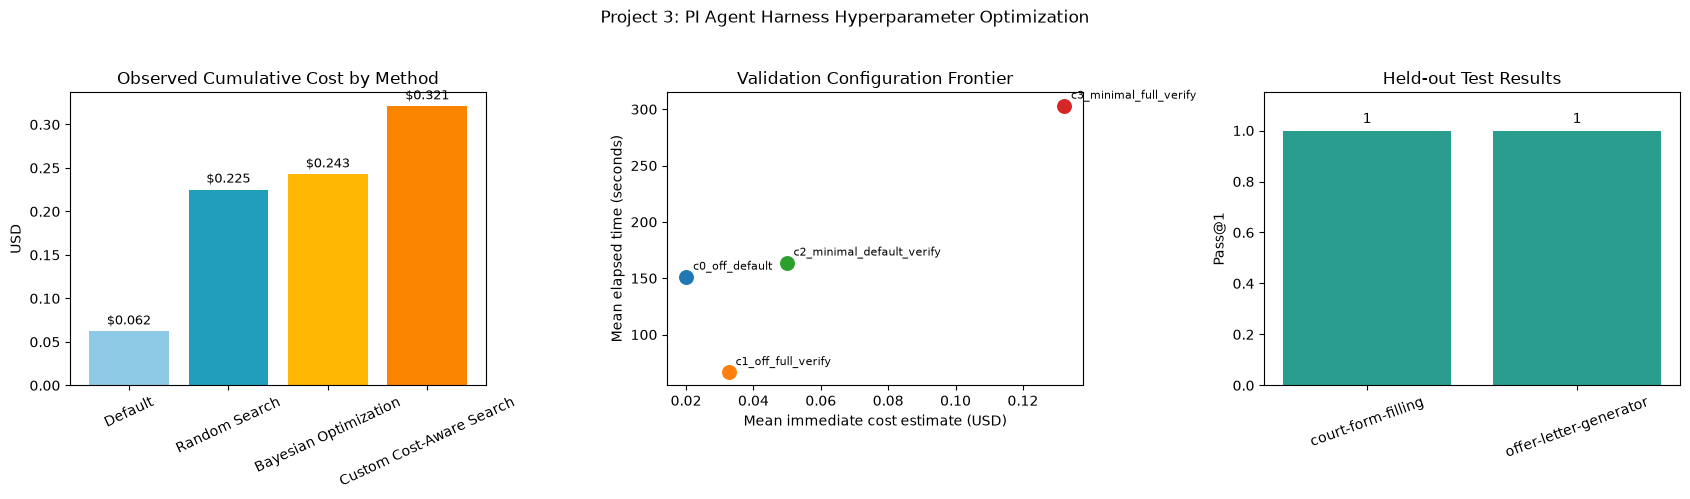

=== Analysis complete ===
Output folder: D:\HuaweiMoveData\Users\86187\Documents\ChatGPT\6203新\project3_pi_hpo_runs\analysis_artifacts

Method comparison:
Default: pass@1=1.0, cost=$0.062066
Random Search: pass@1=1.0, cost=$0.225147
Bayesian Optimization: pass@1=1.0, cost=$0.242667
Custom Cost-Aware Search: pass@1=1.0, cost=$0.320940

Held-out score: 1.0 (2/2 passed)
Frozen configuration: final_c0_off_default


In [19]:
import csv
import json
from pathlib import Path
import matplotlib.pyplot as plt

ANALYSIS_DIR = RUNS_DIR / "analysis_artifacts"
ANALYSIS_DIR.mkdir(exist_ok=True)

def load_root_json(filename):
    return json.loads((RUNS_DIR / filename).read_text(encoding="utf-8"))

baseline = load_root_json("baseline_batch_summary.json")
random_result = load_root_json("random_search_batch_summary.json")
bayes = load_root_json("bayesian_optimization_batch_summary.json")
custom = load_root_json("custom_cost_aware_batch_summary.json")
selection = load_root_json("final_config_selection.json")

# 1. Four-method comparison table
method_rows = [
    {
        "method": "Default",
        "validation_runs": 2,
        "validation_pass_at_1": baseline["formal_validation_pass_at_1"],
        "observed_cumulative_cost_usd": baseline["cumulative_cost_usd_observed"],
        "cost_note": "Includes one dialogue-parser pilot; do not compare this cost directly with the other methods.",
    },
    {
        "method": "Random Search",
        "validation_runs": 6,
        "validation_pass_at_1": 1.0,
        "observed_cumulative_cost_usd": random_result["cumulative_cost_usd_observed"],
        "cost_note": "Primary method-level observed cost.",
    },
    {
        "method": "Bayesian Optimization",
        "validation_runs": 6,
        "validation_pass_at_1": 1.0,
        "observed_cumulative_cost_usd": bayes["cumulative_cost_usd_observed"],
        "cost_note": "Categorical Thompson sampling; primary observed cost.",
    },
    {
        "method": "Custom Cost-Aware Search",
        "validation_runs": 6,
        "validation_pass_at_1": 1.0,
        "observed_cumulative_cost_usd": custom["cumulative_cost_usd_observed"],
        "cost_note": "Two-stage screening and promotion; primary observed cost.",
    },
]

# 2. Configuration-level table used for final selection
config_rows = selection["configuration_metrics"]

# 3. Held-out test table
test_rows = []
for run_dir in sorted(RUNS_DIR.glob("*final_c0_off_default-*")):
    summary_path = run_dir / "summary.json"
    if summary_path.exists():
        item = json.loads(summary_path.read_text(encoding="utf-8"))
        test_rows.append({
            "task": item["task"],
            "pass_at_1": item["pass_at_1"],
            "elapsed_seconds": item["elapsed_seconds"],
            "immediate_cost_estimate_usd": item["cost_usd"],
            "run_id": item["run_id"],
        })

# Save CSV files
def save_csv(path, rows):
    with path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)

save_csv(ANALYSIS_DIR / "method_comparison.csv", method_rows)
save_csv(ANALYSIS_DIR / "configuration_metrics.csv", config_rows)
save_csv(ANALYSIS_DIR / "held_out_test_results.csv", test_rows)

# Create presentation-ready figure
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# A. Method-level observed cost
method_names = [x["method"] for x in method_rows]
method_costs = [x["observed_cumulative_cost_usd"] for x in method_rows]
axes[0].bar(method_names, method_costs, color=["#8ecae6", "#219ebc", "#ffb703", "#fb8500"])
axes[0].set_title("Observed Cumulative Cost by Method")
axes[0].set_ylabel("USD")
axes[0].tick_params(axis="x", rotation=25)
for i, value in enumerate(method_costs):
    axes[0].text(i, value + 0.008, f"${value:.3f}", ha="center", fontsize=9)

# B. Configuration frontier
for item in config_rows:
    axes[1].scatter(
        item["mean_immediate_cost_estimate_usd"],
        item["mean_elapsed_seconds"],
        s=95,
    )
    axes[1].annotate(
        item["label"],
        (item["mean_immediate_cost_estimate_usd"], item["mean_elapsed_seconds"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )
axes[1].set_title("Validation Configuration Frontier")
axes[1].set_xlabel("Mean immediate cost estimate (USD)")
axes[1].set_ylabel("Mean elapsed time (seconds)")

# C. Untouched held-out tests
test_names = [x["task"] for x in test_rows]
test_scores = [x["pass_at_1"] for x in test_rows]
axes[2].bar(test_names, test_scores, color="#2a9d8f")
axes[2].set_ylim(0, 1.15)
axes[2].set_title("Held-out Test Results")
axes[2].set_ylabel("Pass@1")
axes[2].tick_params(axis="x", rotation=20)
for i, value in enumerate(test_scores):
    axes[2].text(i, value + 0.03, f"{value:.0f}", ha="center")

fig.suptitle("Project 3: PI Agent Harness Hyperparameter Optimization", y=1.03)
fig.tight_layout()
figure_path = ANALYSIS_DIR / "experiment_summary.png"
plt.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()

# Short, honest notes for the report
notes = """Project 3 analysis notes

- Formal validation tasks: paper-anonymizer and edit-pdf.
- dialogue-parser was a pilot calibration task and is not part of the formal validation score.
- Held-out tasks: offer-letter-generator and court-form-filling.
- The final configuration was frozen before held-out testing:
  final_c0_off_default = thinking off, default tools, default prompt.
- Both held-out tasks passed, giving held-out pass@1 = 1.0 (2/2).
- OpenRouter per-run immediate cost estimates can lag settlement.
  Use method-level observed cumulative cost as the primary cost metric.
- The default-method cost includes a pilot run, so state this limitation in the report.
- Small benchmark size is a limitation; do not claim broad generalization.
"""
(ANALYSIS_DIR / "analysis_notes.txt").write_text(notes, encoding="utf-8")

print("=== Analysis complete ===")
print("Output folder:", ANALYSIS_DIR)
print("\nMethod comparison:")
for row in method_rows:
    print(
        f"{row['method']}: pass@1={row['validation_pass_at_1']}, "
        f"cost=${row['observed_cumulative_cost_usd']:.6f}"
    )

print("\nHeld-out score:", sum(test_scores) / len(test_scores), f"({len(test_scores)}/2 passed)")
print("Frozen configuration:", selection["frozen_final_config"]["label"])